In [1]:
import numpy as np
from scipy.io import wavfile
import IPython.display as ipd
from scipy import signal as sig
from scipy.linalg import solve_toeplitz
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
%config InlineBackend.figure_format = 'svg'

import Funciones as Funciones
from NNMF_GIF import NNMF_GIF
from MetricasRendimiento import MetricasRendimiento

In [14]:
datos = np.loadtxt("Resultados beta - todas.txt", delimiter="\t", skiprows=1)
mediana1_todas = datos[:, 0]
p25_1_todas    = datos[:, 1]
p75_1_todas    = datos[:, 2]

datos = np.loadtxt("Resultados beta - señales hombre.txt", delimiter="\t", skiprows=1)
mediana1_completo_hombre = datos[:, 0]
p25_1_completo_hombre    = datos[:, 1]
p75_1_completo_hombre    = datos[:, 2]

datos = np.loadtxt("Resultados beta - señales mujer.txt", delimiter="\t", skiprows=1)
mediana1_completo_mujer = datos[:, 0]
p25_1_completo_mujer    = datos[:, 1]
p75_1_completo_mujer    = datos[:, 2]

datos = np.loadtxt("Resultados beta - baja frecuencia.txt", delimiter="\t", skiprows=1)
mediana1_baja_frecuecnia = datos[:, 0]
p25_1_baja_frecuecnia    = datos[:, 1]
p75_1_baja_frecuecnia    = datos[:, 2]

datos = np.loadtxt("Resultados beta - media frecuencia.txt", delimiter="\t", skiprows=1)
mediana1_media_frecuecnia = datos[:, 0]
p25_1_media_frecuecnia    = datos[:, 1]
p75_1_media_frecuecnia    = datos[:, 2]


datos = np.loadtxt("Resultados beta - alta frecuencia.txt", delimiter="\t", skiprows=1)
mediana1_alta_frecuecnia = datos[:, 0]
p25_1_alta_frecuecnia    = datos[:, 1]
p75_1_alta_frecuecnia    = datos[:, 2]

datos = np.loadtxt("Resultados beta - Completo A.txt", delimiter="\t", skiprows=1)
mediana1_A = datos[:, 0]
p25_1_A   = datos[:, 1]
p75_1_A   = datos[:, 2]

datos = np.loadtxt("Resultados beta - Completo AE.txt", delimiter="\t", skiprows=1)
mediana1_AE = datos[:, 0]
p25_1_AE   = datos[:, 1]
p75_1_AE   = datos[:, 2]

datos = np.loadtxt("Resultados beta - Completo I.txt", delimiter="\t", skiprows=1)
mediana1_I = datos[:, 0]
p25_1_I   = datos[:, 1]
p75_1_I   = datos[:, 2]

datos = np.loadtxt("Resultados beta - Completo U.txt", delimiter="\t", skiprows=1)
mediana1_U = datos[:, 0]
p25_1_U   = datos[:, 1]
p75_1_U   = datos[:, 2]

p = np.arange(0.20,2.0,0.01)


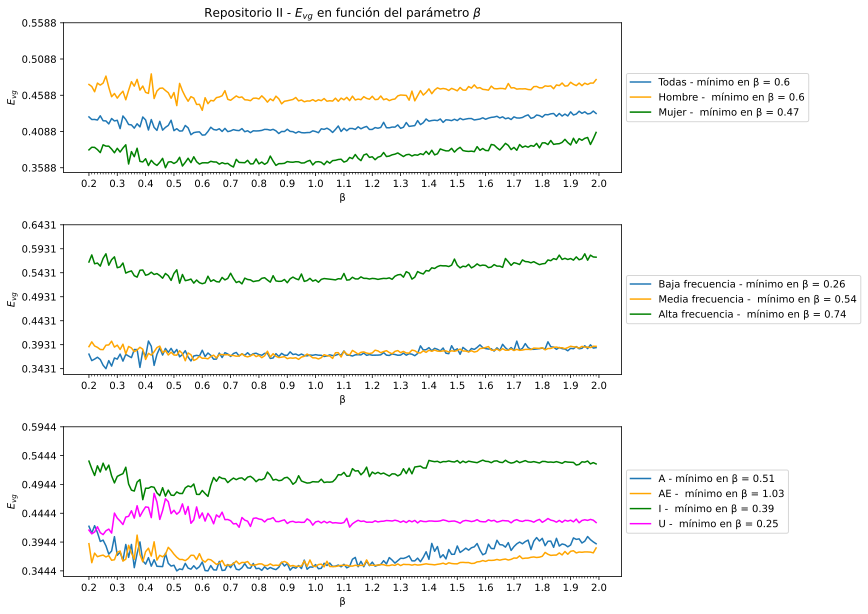

In [53]:
fig,ax = plt.subplots(3,1,figsize=(10,10))
fig.subplots_adjust(hspace=0.35)
legend_loc = 'best'

xbbox = 1.0
ybbox = 0.65    
alfa_grid = 0.3





ax[0].plot(p,mediana1_todas,label=f'Todas - mínimo en β = {round(p[np.argmin(mediana1_todas)],3)}')
#ax[0].scatter(p[np.argmin(mediana1_todas)],min(mediana1_todas),s=20,marker='x',zorder=99)
ax[0].plot(p,mediana1_completo_hombre,color='orange',label= f'Hombre -  mínimo en β = {round(p[np.argmin(mediana1_completo_hombre)],3)}')
#ax[0].scatter(p[np.argmin(mediana1_completo_hombre)],min(mediana1_completo_hombre),s=20,marker='x',zorder=99)
ax[0].plot(p,mediana1_completo_mujer,color='green',label=f'Mujer -  mínimo en β = {round(p[np.argmin(mediana1_completo_mujer)],3)}')

ax[0].set_yticks(np.arange(min([min(mediana1_todas),min(mediana1_completo_hombre),min(mediana1_completo_mujer)]),
                           max([max(mediana1_todas),max(mediana1_completo_hombre),max(mediana1_completo_mujer)])+0.1,0.05))

#ax[0].scatter(p[np.argmin(mediana1_completo_mujer)],min(mediana1_completo_mujer),color='green',s=20,marker='x',zorder=99)
#ax[0].legend(bbox_to_anchor=(xbbox, ybbox))

ax[1].plot(p,mediana1_baja_frecuecnia,label=f'Baja frecuencia - mínimo en β = {round(p[np.argmin(mediana1_baja_frecuecnia)],3)}')
ax[1].plot(p,mediana1_media_frecuecnia,color='orange',label= f'Media frecuencia -  mínimo en β = {round(p[np.argmin(mediana1_media_frecuecnia)],3)}')
ax[1].plot(p,mediana1_alta_frecuecnia,color='green',label=f'Alta frecuencia -  mínimo en β = {round(p[np.argmin(mediana1_alta_frecuecnia)],3)}')
ax[1].set_yticks(np.arange(min([min(mediana1_baja_frecuecnia),min(mediana1_media_frecuecnia),min(mediana1_alta_frecuecnia)]),
                           max([max(mediana1_baja_frecuecnia),max(mediana1_media_frecuecnia),max(mediana1_alta_frecuecnia)])+0.1,0.05))

ax[2].plot(p,mediana1_A,label=f'A - mínimo en β = {round(p[np.argmin(mediana1_A)],3)}')
ax[2].plot(p,mediana1_AE,color='orange',label= f'AE -  mínimo en β = {round(p[np.argmin(mediana1_AE)],3)}')
ax[2].plot(p,mediana1_I,color='green',label=f'I -  mínimo en β = {round(p[np.argmin(mediana1_I)],3)}')
ax[2].plot(p,mediana1_U,color='magenta',label=f'U -  mínimo en β = {round(p[np.argmin(mediana1_U)],3)}')
ax[2].set_yticks(np.arange(min([min(mediana1_A),min(mediana1_AE),min(mediana1_I),min(mediana1_U)]),
                           max([max(mediana1_A),max(mediana1_AE),max(mediana1_I),max(mediana1_U)])+0.1,0.05))

for ax_ in ax:
    ax_.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
    ax_.set_xticks(np.arange(p[0],p[-1]+0.1,0.1))
    ax_.set_xticks(np.arange(p[0],p[-1],0.01),minor=True)
    ax_.set_xlabel("β");
    ax_.set_ylabel(r"$E_{vg}$");
ax[0].set_title(r"Repositorio II - $E_{vg}$ en función del parámetro $\beta$");
fig.savefig("Comparación beta.pdf",bbox_inches = 'tight')